# 03 Validación, modelos y evaluacion

Este notebook cubre los puntos 9 (estrategia de validación) y 10 (construcción y evaluación del modelo), y calcula el impacto que se usa en las conclusiones (punto 13). El flujo es:

- Division estratificada 60/20/20, imputacion y escalado con el conjunto de entrenamiento, regresión logistica, árbol de decision y KNN con GridSearchCV, y despues Random Forest, Gradient Boosting, votacion, stacking y una red neuronal con Keras. El modelo se escoge por F1 en validación y la prueba se usa una sola vez.
- Prueba de McNemar y bootstrapping pareado para comparar modelos, e impacto con la fórmula de Provost.
- Interpretación con SHAP.

Pregunta que responde el modelo: dado un par de facturas del mismo proveedor con el mismo monto, ¿qué tan probable es que sea un cobro repetido como los que el Banco ya ha anulado, disputado o rechazado?

Relacion entre hipótesis y tecnicas (comentario de la entrega 1):

- H1. Las facturas del mismo proveedor con el mismo monto, fecha cercana o número casi idéntico son más riesgosas (cómo se responde en esta entrega: Modelos de clasificación del par, comparados contra la regla de la entrega 1 con McNemar y bootstrapping; sección: 4 a 8)
- H2. El canal influye en el riesgo (cómo se responde en esta entrega: Chi cuadrado y V de Cramér entre el canal y la etiqueta, y efecto del canal en SHAP; sección: 9)
- H3. Los proveedores nuevos tienen más anomalías (cómo se responde en esta entrega: Chi cuadrado por tercil de historia del proveedor, y efecto en SHAP; sección: 9)
- H4. Los montos atipicos tienen más fricción (cómo se responde en esta entrega: Chi cuadrado por cuartil de monto, y efecto en SHAP; sección: 9)

La agrupacion de proveedores duplicados (objetivo 3) esta en el notebook 04.


In [15]:
%pip install -r ../requirements.txt

  Using cached pandas-3.0.5-cp311-cp311-win_amd64.whl.metadata (19 kB)
Note: you may need to restart the kernel to use updated packages.


ERROR: Ignored the following yanked versions: 2.4.0
ERROR: Ignored the following versions that require a different python version: 1.21.2 Requires-Python >=3.7,<3.11; 1.21.3 Requires-Python >=3.7,<3.11; 1.21.4 Requires-Python >=3.7,<3.11; 1.21.5 Requires-Python >=3.7,<3.11; 1.21.6 Requires-Python >=3.7,<3.11; 2.5.0 Requires-Python >=3.12; 2.5.0rc1 Requires-Python >=3.12; 2.5.1 Requires-Python >=3.12; 2.5.2 Requires-Python >=3.12; 2.5.3 Requires-Python >=3.12; 2.5.4 Requires-Python >=3.12; 2.5.5 Requires-Python >=3.12
ERROR: Could not find a version that satisfies the requirement numpy==2.5.3 (from versions: 1.3.0, 1.4.1, 1.5.0, 1.5.1, 1.6.0, 1.6.1, 1.6.2, 1.7.0, 1.7.1, 1.7.2, 1.8.0, 1.8.1, 1.8.2, 1.9.0, 1.9.1, 1.9.2, 1.9.3, 1.10.0.post2, 1.10.1, 1.10.2, 1.10.4, 1.11.0, 1.11.1, 1.11.2, 1.11.3, 1.12.0, 1.12.1, 1.13.0, 1.13.1, 1.13.3, 1.14.0, 1.14.1, 1.14.2, 1.14.3, 1.14.4, 1.14.5, 1.14.6, 1.15.0, 1.15.1, 1.15.2, 1.15.3, 1.15.4, 1.16.0, 1.16.1, 1.16.2, 1.16.3, 1.16.4, 1.16.5, 1.16.6, 1.17

## 1. Configuración y carga


In [16]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier,VotingClassifier,StackingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,
                              average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                           PrecisionRecallDisplay,RocCurveDisplay)
from statsmodels.stats.contingency_tables import mcnemar
import shap

pd.set_option("display.width",200)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42
ALPHA = 0.05
PARES_PATH = "../data/processed/pares.parquet"
REVISION_BANCO = "../data/raw/Revision_casos_duplicados_Banco_respuesta.xlsx"

pares = pd.read_parquet(PARES_PATH)
VARS_CONTINUAS = ["dias_entre_facturas", "similitud_numero", "distancia_periodo", "log_monto", "log_historia_proveedor"]
VARS_BINARIAS = ["mismo_numero_normalizado", "mismo_canal", "mismo_metodo"] + [
  c for c in pares.columns if c.startswith("canal_") or c.startswith("moneda_")]
VARS=VARS_CONTINUAS + VARS_BINARIAS
print(f"Pares: {len(pares):,} | positivos: {pares['y'].sum():,} ({pares['y'].mean():.2%}) | variables: {len(VARS)}")

def ic_bootstrap(aciertos, B=1000):
    # IC por bootstrapping y no con la formula normal: la proporcion de los primeros k no es grande
    rng = np.random.default_rng(42)
    aciertos = np.asarray(aciertos)
    medias = [rng.choice(aciertos, len(aciertos), replace=True).mean() for _ in range(B)]
    return aciertos.mean(),np.percentile(medias,2.5),np.percentile(medias,97.5)

Pares: 11,455 | positivos: 1,086 (9.48%) | variables: 14


## 2. Estrategia de validación (punto 9)

Se usa una división estratificada en tres conjuntos: 60% entrenamiento, 20% validacion y 20% prueba, con random_state=42. Se estratifica porque la clase positiva es solo el 9,5% de los pares, y sin estratificar un conjunto podria quedar con muchos menos positivos que otro.

- Entrenamiento: se ajustan la imputacion, el escalado y los modelos, y se buscan hiperparámetros con validacion cruzada de 5 folds.
- Validacion: se comparan los modelos y se escoge el mejor por F1.
- Prueba: se usa una sola vez, con el modelo ya escogido.


In [17]:
X = pares[VARS]
y = pares["y"]
# estratificado porque solo el 9,5% son positivos
X_temp,X_test,y_temp,y_test=train_test_split(
  X, y, test_size=0.2, random_state=42, stratify=y
)
X_train,X_val,y_train,y_val = train_test_split(
      X_temp,y_temp,test_size=0.25,random_state=42,stratify=y_temp
)
print(f"Entrenamiento: {len(X_train):,} | validación: {len(X_val):,} | prueba: {len(X_test):,}")
print(y_train.value_counts(normalize=True),y_val.value_counts(normalize=True),y_test.value_counts(normalize=True))

Entrenamiento: 6,873 | validación: 2,291 | prueba: 2,291
y
0   0.905
1   0.095
Name: proportion, dtype: float64 y
0   0.905
1   0.095
Name: proportion, dtype: float64 y
0   0.905
1   0.095
Name: proportion, dtype: float64


El enunciado pide verificar que la distribución de cada subconjunto se conserva frente al conjunto original. La tabla compara la proporción de positivos y el promedio de cada variable.


In [18]:
tabla_dist = pd.DataFrame({
    "total": pd.concat([X, y], axis=1).mean(),
      "entrenamiento": pd.concat([X_train, y_train], axis=1).mean(),
  "validación": pd.concat([X_val,y_val],axis=1).mean(),
      "prueba": pd.concat([X_test, y_test], axis=1).mean(),
})
tabla_dist["diferencia máx. vs total (%)"] = ((tabla_dist[["entrenamiento", "validación", "prueba"]]
                                             .sub(tabla_dist["total"], axis=0).abs().max(axis=1))
                                           / tabla_dist["total"].abs() * 100)
tabla_dist

,total,entrenamiento,validación,prueba,diferencia máx. vs total (%)
dias_entre_facturas,25.868,25.818,25.826,26.061,0.744
similitud_numero,0.735,0.734,0.739,0.733,0.604
distancia_periodo,15.497,15.494,15.825,15.179,2.120
log_monto,4.489,4.479,4.512,4.493,0.525
log_historia_proveedor,5.692,5.684,5.672,5.738,0.798
mismo_numero_normalizado,0.003,0.002,0.003,0.005,93.548
mismo_canal,0.972,0.974,0.971,0.969,0.386
mismo_metodo,0.950,0.952,0.948,0.949,0.285
canal_email,0.022,0.022,0.022,0.024,9.375
canal_otro,0.009,0.008,0.011,0.010,20.370


La proporción de positivos es la misma en los tres conjuntos gracias a la estratificación, y los promedios de las variables se mueven poco frente al total. Las únicas diferencias relativas grandes estan en categorias muy pequeñas (por ejemplo el canal "otro" o la moneda "otra"), donde unos pocos pares cambian mucho el porcentaje.


### 2.1 Imputación y escalado

La similitud del número tiene 27 valores faltantes. Se imputan con la mediana del conjunto de entrenamiento y ese mismo valor se aplica a validación y prueba. Después se estandarizan solo las variables continuas, ajustando el escalador con entrenamiento; las variables 0/1 se dejan como están porque ya están en la misma escala.


In [19]:
# la mediana sale solo de train para no meter fuga
mediana_similitud=X_train["similitud_numero"].median()
for d in (X_train, X_val, X_test):
    d["similitud_numero"] = d["similitud_numero"].fillna(mediana_similitud)
print("Mediana de entrenamiento usada para imputar:", round(mediana_similitud, 4))
# las 0/1 no se escalan
escalador = StandardScaler()
X_train_esc,X_val_esc,X_test_esc = X_train.copy(),X_val.copy(),X_test.copy()
X_train_esc[VARS_CONTINUAS] = escalador.fit_transform(X_train[VARS_CONTINUAS])
X_val_esc[VARS_CONTINUAS] = escalador.transform(X_val[VARS_CONTINUAS])
X_test_esc[VARS_CONTINUAS] = escalador.transform(X_test[VARS_CONTINUAS])

Mediana de entrenamiento usada para imputar: 0.7692


## 3. Métricas y linea base

Para cada modelo se calculan exactitud, precisión, recall, F1, AUC y AP en entrenamiento y validacion. La exactitud no sirve para escoger: un modelo que dijera siempre "no" acertaría el 90% de las veces sin encontrar ningún duplicado.

La línea base es la regla de la entrega 1: marcar el par si las dos facturas llegaron a 7 días o menos o si el número normalizado es idéntico. Un modelo solo vale la pena si le gana a esta regla.


In [20]:
def metricas(y_real, y_pred, y_prob):
    return {"exactitud": accuracy_score(y_real,y_pred),"precisión": precision_score(y_real,y_pred,zero_division=0),
           "recall": recall_score(y_real, y_pred), "F1": f1_score(y_real, y_pred),
          "AUC": roc_auc_score(y_real, y_prob), "AP": average_precision_score(y_real, y_prob)}

def evaluar(nombre, modelo):
    fila = {"modelo": nombre}
    for conj,Xc,yc in [("train",X_train_esc,y_train),("val",X_val_esc,y_val)]:
        m=metricas(yc, modelo.predict(Xc), modelo.predict_proba(Xc)[:, 1])
        fila.update({f"{k} {conj}": v for k,v in m.items()})
    return fila

def regla_base(Xc):
    # la regla usa los días sin escalar
    return ((Xc["dias_entre_facturas"] <= 7) | (Xc["mismo_numero_normalizado"] == 1)).astype(int).to_numpy()

fila={"modelo": "Regla de la entrega 1"}
for conj, Xc, yc in [("train", X_train, y_train), ("val", X_val, y_val)]:
    pred = regla_base(Xc)
    fila.update({f"{k} {conj}": v for k,v in metricas(yc,pred,pred).items()})
resultados = [fila]
pd.DataFrame(resultados).set_index("modelo").round(3)

,exactitud train,precisión train,recall train,F1 train,AUC train,AP train,exactitud val,precisión val,recall val,F1 val,AUC val,AP val
modelo,,,,,,,,,,,,
Regla de la entrega 1,0.678,0.126,0.403,0.192,0.555,0.108,0.670,0.123,0.406,0.189,0.552,0.106


## 4. Modelos basicos

Se buscan los hiperparámetros con GridSearchCV, validacion cruzada estratificada de 5 folds y F1 como métrica. Se optimiza F1 y no exactitud porque lo que importa es encontrar los pares positivos sin llenar la cola de falsos positivos.


In [21]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
busqueda_logistica = GridSearchCV(LogisticRegression(max_iter=1000),
                               {"C": [0.01, 0.1, 1, 10], "class_weight": [None, "balanced"]},
                                    cv=cv,scoring="f1",n_jobs=-1)
busqueda_logistica.fit(X_train_esc, y_train)
print("Regresión logística · mejor combinación:",busqueda_logistica.best_params_,"| F1 CV:",round(busqueda_logistica.best_score_,3))
resultados.append(evaluar("Regresión logística",busqueda_logistica.best_estimator_))

Regresión logística · mejor combinación: {'C': 10, 'class_weight': 'balanced'} | F1 CV: 0.297


In [22]:
busqueda_arbol = GridSearchCV(DecisionTreeClassifier(random_state=42),
                               {"max_depth": [3,5,8,None],"min_samples_leaf": [1,20,50],"class_weight": [None,"balanced"]},
                                cv=cv, scoring="f1", n_jobs=-1)
busqueda_arbol.fit(X_train_esc, y_train)
print("Árbol de decisión · mejor combinación:", busqueda_arbol.best_params_, "| F1 CV:", round(busqueda_arbol.best_score_, 3))
resultados.append(evaluar("Árbol de decisión", busqueda_arbol.best_estimator_))

Árbol de decisión · mejor combinación: {'class_weight': None, 'max_depth': None, 'min_samples_leaf': 1} | F1 CV: 0.35


KNN mide distancias entre pares, asi que necesita las variables escaladas; si no, los días (de 0 a 90) pesarían mucho mas que la similitud del número (de 0 a 1).


In [23]:
busqueda_knn = GridSearchCV(KNeighborsClassifier(),
                           {"n_neighbors": [5, 15, 31, 51], "weights": ["uniform", "distance"]},
                              cv=cv, scoring="f1", n_jobs=-1)
busqueda_knn.fit(X_train_esc,y_train)
print("KNN · mejor combinación:", busqueda_knn.best_params_, "| F1 CV:", round(busqueda_knn.best_score_, 3))
resultados.append(evaluar("KNN", busqueda_knn.best_estimator_))

KNN · mejor combinación: {'n_neighbors': 5, 'weights': 'distance'} | F1 CV: 0.318


## 5. Ensambles

Para Random Forest se prueban profundidades y hojas más restrictivas, para ver si se controla el sobreajuste. Gradient Boosting no tiene class_weight, así que se le pasan pesos balanceados por registro con compute_sample_weight.


In [24]:
busqueda_rf = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                        {"n_estimators": [200, 400], "max_depth": [5, 10, None], "min_samples_leaf": [1, 5, 20],
                            "class_weight": [None,"balanced"]},
                            cv=cv, scoring="f1", n_jobs=-1)
busqueda_rf.fit(X_train_esc, y_train)
print("Random Forest · mejor combinación:", busqueda_rf.best_params_, "| F1 CV:", round(busqueda_rf.best_score_, 3))
resultados.append(evaluar("Random Forest", busqueda_rf.best_estimator_))

Random Forest · mejor combinación: {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 200} | F1 CV: 0.415


In [25]:
# GB no tiene class_weight, toca con pesos por registro
pesos = compute_sample_weight("balanced",y_train)
busqueda_gb=GridSearchCV(GradientBoostingClassifier(random_state=42),
                         {"n_estimators": [100, 300], "learning_rate": [0.05, 0.1], "max_depth": [2, 3, 4]},
                        cv=cv,scoring="f1",n_jobs=-1)
busqueda_gb.fit(X_train_esc, y_train, sample_weight=pesos)
print("Gradient Boosting · mejor combinación:", busqueda_gb.best_params_, "| F1 CV:", round(busqueda_gb.best_score_, 3))
resultados.append(evaluar("Gradient Boosting", busqueda_gb.best_estimator_))

Gradient Boosting · mejor combinación: {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 300} | F1 CV: 0.653


In [26]:
modelos_base = [
    ("logistica", busqueda_logistica.best_estimator_),
  ("arbol", busqueda_arbol.best_estimator_),
    ("knn", busqueda_knn.best_estimator_),
]
votacion_dura = VotingClassifier(estimators=modelos_base,voting="hard")
votacion_dura.fit(X_train_esc, y_train)
votacion_suave = VotingClassifier(estimators=modelos_base,voting="soft")
votacion_suave.fit(X_train_esc, y_train)
print(f"F1 en validación · votación dura: {f1_score(y_val, votacion_dura.predict(X_val_esc)):.3f} | "
   f"votación suave: {f1_score(y_val, votacion_suave.predict(X_val_esc)):.3f}")
resultados.append(evaluar("Votación suave", votacion_suave))

F1 en validación · votación dura: 0.383 | votación suave: 0.349


In [27]:
busqueda_stacking = GridSearchCV(
      StackingClassifier(estimators=modelos_base, final_estimator=LogisticRegression(max_iter=1000), cv=5,
                         stack_method="predict_proba", n_jobs=-1),
      {"final_estimator__C": [0.1, 1, 10], "final_estimator__class_weight": [None, "balanced"]},
 cv=cv,scoring="f1")
busqueda_stacking.fit(X_train_esc, y_train)
print("Stacking · mejor combinación:",busqueda_stacking.best_params_,"| F1 CV:",round(busqueda_stacking.best_score_,3))
print("Pesos del meta-modelo (logística, árbol, KNN):",busqueda_stacking.best_estimator_.final_estimator_.coef_.round(3))
resultados.append(evaluar("Stacking", busqueda_stacking.best_estimator_))

Stacking · mejor combinación: {'final_estimator__C': 0.1, 'final_estimator__class_weight': 'balanced'} | F1 CV: 0.342
Pesos del meta-modelo (logística, árbol, KNN): [[2.378 0.888 2.358]]


Nota sobre Gradient Boosting: su F1 de validacion cruzada sale mucho más alto que el de los demas porque GridSearchCV también usa los pesos balanceados al calcular el F1 de cada fold, y eso le da más peso a los positivos. Por eso los modelos se comparan con el F1 de validación de la tabla siguiente, que se calcula igual para todos.


### 5.1 Red neuronal

Para ver si un modelo más complejo le gana a los árboles se prueba una red densa con Keras: capas Dense con ReLU, Dropout(0.2) despues de cada capa oculta, una neurona de salida con sigmoide, optimizador Adam y perdida binary_crossentropy. Se comparan tres arquitecturas (8, 16-8 y 32-16-8 neuronas) con 100 epocas, batch_size de 32 y el conjunto de validacion como validation_data, y se escoge la de mayor F1 en validación. Como solo el 9,5% de los pares son positivos, a fit se le pasa class_weight balanceado, que es lo mismo que class_weight="balanced" en los otros modelos. La red usa las mismas variables escaladas que la logistica y KNN.


In [28]:
import keras
from keras import layers

# mismos pesos que class_weight="balanced" de los otros modelos
n0, n1 = (y_train==0).sum(), (y_train==1).sum()
pesos_clase = {0: len(y_train) / (2*n0), 1: len(y_train) / (2*n1)}

def crear_red(capas):
    keras.utils.set_random_seed(42)
    ocultas = []
    for n in capas:
        ocultas += [layers.Dense(n, activation="relu"), layers.Dropout(0.2)]
    model = keras.Sequential([keras.Input(shape=(X_train_esc.shape[1],))] + ocultas + [layers.Dense(1, activation="sigmoid")])
    model.compile(optimizer="adam", loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="auc"), keras.metrics.Recall(name="recall")])
    return model

class RedKeras:
    # para comparar la red igual que los modelos de sklearn
    def __init__(self, red):
        self.red = red
    def predict_proba(self, X):
        p = self.red.predict(np.asarray(X, dtype="float32"), verbose=0).ravel()
        return np.column_stack([1 - p, p])
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

arquitecturas = {"a) 8": [8], "b) 16-8": [16, 8], "c) 32-16-8": [32, 16, 8]}
redes, historias = {}, {}
for nombre, capas in arquitecturas.items():
    red = crear_red(capas)
    historias[nombre] = red.fit(X_train_esc.astype("float32"), y_train,
                                validation_data=(X_val_esc.astype("float32"), y_val),
                                epochs=100, batch_size=32, class_weight=pesos_clase, verbose=0)
    redes[nombre] = RedKeras(red)
    print(f"Arquitectura {nombre} | parametros: {red.count_params()} | F1 val: {f1_score(y_val, redes[nombre].predict(X_val_esc)):.3f}")

f1_redes = {n: f1_score(y_val, r.predict(X_val_esc)) for n, r in redes.items()}
mejor_arq = max(f1_redes, key=f1_redes.get)
red_final = redes[mejor_arq]
print("Mejor arquitectura:", mejor_arq)
resultados.append(evaluar("Red neuronal", red_final))


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.3.5 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\maria\AppData\Roaming\Python\Python311\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\maria\AppData\Roaming\Python\Python311\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\maria\AppData\Roaming\Python\Python311\site-packages\ipykernel\kernelapp.py", line 739, in start
    self.io_lo

AttributeError: _ARRAY_API not found

ImportError: numpy.core._multiarray_umath failed to import

ImportError: numpy.core.umath failed to import

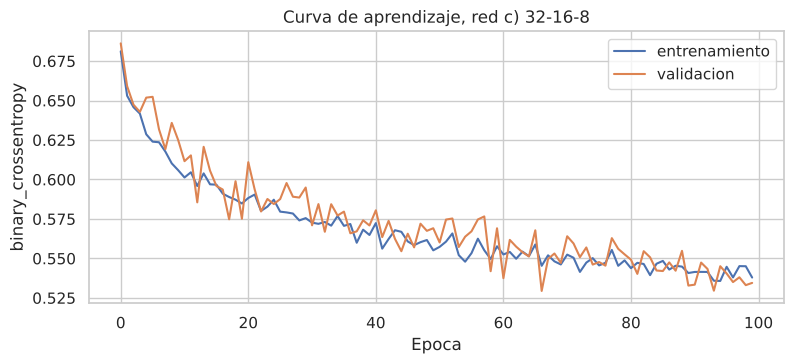

In [ ]:
h = historias[mejor_arq].history
plt.figure(figsize=(8, 3.8))
plt.plot(h["loss"], label="entrenamiento"); plt.plot(h["val_loss"], label="validacion")
plt.xlabel("Epoca"); plt.ylabel("binary_crossentropy"); plt.title(f"Curva de aprendizaje, red {mejor_arq}")
plt.legend(); plt.tight_layout(); plt.show()

## 6. Comparacion en entrenamiento y validación


In [ ]:
tabla = pd.DataFrame(resultados).set_index("modelo")
tabla["brecha F1 (train - val)"] = tabla["F1 train"] - tabla["F1 val"]
cols=["exactitud val", "precisión val", "recall val", "F1 val", "AUC val", "AP val", "F1 train", "brecha F1 (train - val)"]
tabla[cols].sort_values("F1 val",ascending=False).round(3)

,exactitud val,precisión val,recall val,F1 val,AUC val,AP val,F1 train,brecha F1 (train - val)
modelo,,,,,,,,
Random Forest,0.903,0.485,0.369,0.419,0.792,0.438,0.994,0.575
Votación suave,0.891,0.401,0.309,0.349,0.753,0.375,1.000,0.651
Stacking,0.781,0.238,0.594,0.340,0.758,0.394,0.735,0.396
Árbol de decisión,0.870,0.322,0.336,0.329,0.631,0.171,1.000,0.671
Red neuronal,0.793,0.237,0.535,0.329,0.740,0.355,0.426,0.098
KNN,0.910,0.562,0.230,0.327,0.709,0.333,1.000,0.673
Gradient Boosting,0.770,0.223,0.576,0.322,0.759,0.351,0.431,0.109
Regresión logística,0.718,0.179,0.548,0.270,0.701,0.286,0.300,0.030
Regla de la entrega 1,0.670,0.123,0.406,0.189,0.552,0.106,0.192,0.003


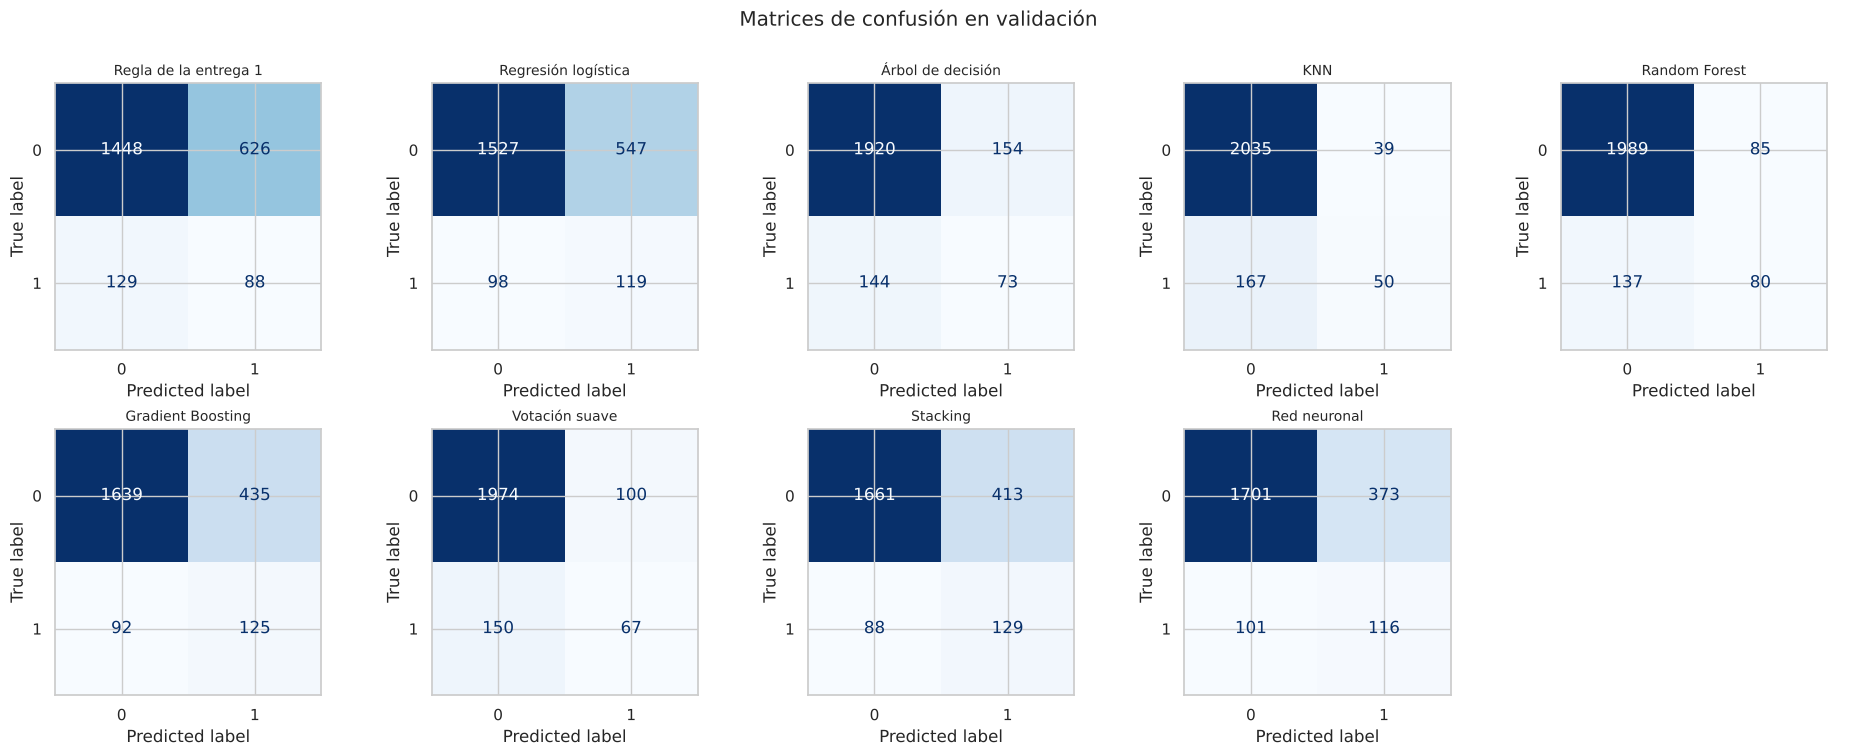

In [ ]:
modelos = {"Regresión logística": busqueda_logistica.best_estimator_, "Árbol de decisión": busqueda_arbol.best_estimator_,
           "KNN": busqueda_knn.best_estimator_, "Random Forest": busqueda_rf.best_estimator_,
           "Gradient Boosting": busqueda_gb.best_estimator_, "Votación suave": votacion_suave,
          "Stacking": busqueda_stacking.best_estimator_, "Red neuronal": red_final}
fig, axes=plt.subplots(2, 5, figsize=(19, 7.5))
ConfusionMatrixDisplay.from_predictions(y_val,regla_base(X_val),ax=axes[0,0],colorbar=False,cmap="Blues")
axes[0,0].set_title("Regla de la entrega 1",fontsize=10)
for ax,(nombre,m) in zip(axes.ravel()[1:],modelos.items()):
    ConfusionMatrixDisplay.from_predictions(y_val, m.predict(X_val_esc), ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(nombre, fontsize=10)
axes[1,4].axis("off")
plt.suptitle("Matrices de confusión en validación", y=1.0); plt.tight_layout()
plt.show()

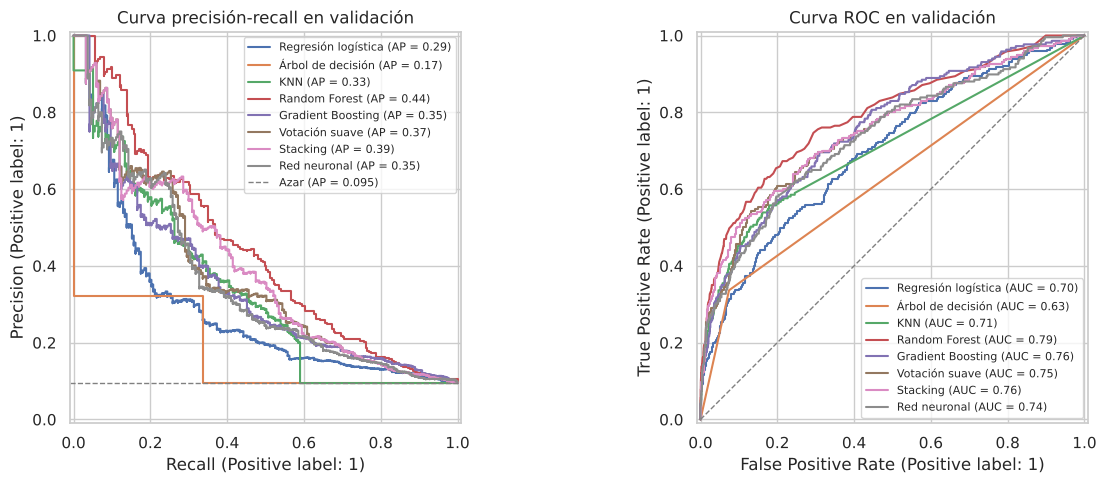

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for nombre, m in modelos.items():
    p_val = m.predict_proba(X_val_esc)[:,1]  # from_predictions porque la red no es de sklearn
    PrecisionRecallDisplay.from_predictions(y_val, p_val, ax=axes[0], name=nombre)
    RocCurveDisplay.from_predictions(y_val, p_val, ax=axes[1], name=nombre)
axes[0].axhline(y_val.mean(),color="grey",ls="--",lw=1,label=f"Azar (AP = {y_val.mean():.3f})")
axes[1].plot([0,1],[0,1],color="grey",ls="--",lw=1)
axes[0].set_title("Curva precisión-recall en validación"); axes[1].set_title("Curva ROC en validación")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8); plt.tight_layout()
plt.show()

## 7. Seleccion del modelo

Se escoge el modelo con mayor F1 en validación. Si dos quedan a menos de 0,01, se prefiere el de menor brecha entre entrenamiento y validacion.


In [ ]:
ranking = tabla.drop(index="Regla de la entrega 1").sort_values("F1 val",ascending=False)
mejor_nombre,segundo_nombre = ranking.index[0],ranking.index[1]
if ranking.loc[mejor_nombre, "F1 val"] - ranking.loc[segundo_nombre, "F1 val"] < 0.01 and \
   ranking.loc[segundo_nombre, "brecha F1 (train - val)"] < ranking.loc[mejor_nombre, "brecha F1 (train - val)"]:
    mejor_nombre,segundo_nombre=segundo_nombre,mejor_nombre
mejor,segundo = modelos[mejor_nombre],modelos[segundo_nombre]
print(f"Modelo escogido: {mejor_nombre} | F1 val {tabla.loc[mejor_nombre, 'F1 val']:.3f} | brecha {tabla.loc[mejor_nombre, 'brecha F1 (train - val)']:.3f}")
print(f"Segundo:         {segundo_nombre} | F1 val {tabla.loc[segundo_nombre, 'F1 val']:.3f} | brecha {tabla.loc[segundo_nombre, 'brecha F1 (train - val)']:.3f}")

Modelo escogido: Random Forest | F1 val 0.419 | brecha 0.575
Segundo:         Votación suave | F1 val 0.349 | brecha 0.651


El Random Forest tiene la brecha más grande entre entrenamiento y validación, porque con min_samples_leaf=1 y sin límite de profundidad cada árbol casi memoriza el entrenamiento. Aun así es el mejor en validación por una diferencia clara frente al segundo, así que se mantiene: lo que importa es su desempeño en datos que no vio. Limitar la profundidad o subir min_samples_leaf (que si estaban en la grilla) dio menor F1 en la validación cruzada.


## 8. Evaluación en prueba

La prueba se usa una sola vez, con el modelo ya escogido. Ademas de las metricas de clasificacion se calcula la metrica del enfoque analítico de la entrega 1: la precisión en los primeros k pares ordenados por puntaje (precisión@k), con su intervalo de confianza por bootstrapping. Ojo: aqui un acierto es un par con fricción (la etiqueta aproximada), no un duplicado confirmado.


In [ ]:
y_pred_a = mejor.predict(X_test_esc)
y_pred_b = segundo.predict(X_test_esc)
y_pred_regla = regla_base(X_test)
y_prob_a = mejor.predict_proba(X_test_esc)[:, 1]
tabla_test = pd.DataFrame({mejor_nombre: metricas(y_test,y_pred_a,y_prob_a),
                        segundo_nombre: metricas(y_test,y_pred_b,segundo.predict_proba(X_test_esc)[:,1]),
                           "Regla de la entrega 1": metricas(y_test, y_pred_regla, y_pred_regla)}).T
tabla_test.round(3)

,exactitud,precisión,recall,F1,AUC,AP
Random Forest,0.906,0.506,0.387,0.439,0.780,0.449
Votación suave,0.894,0.437,0.401,0.418,0.755,0.403
Regla de la entrega 1,0.701,0.155,0.484,0.234,0.604,0.124


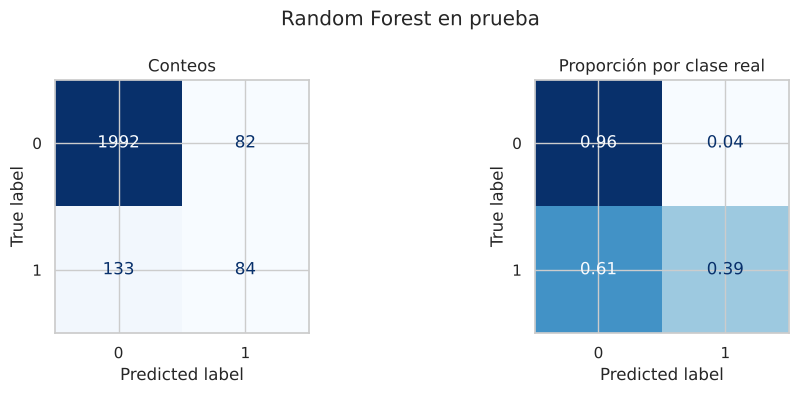

In [ ]:
fig, axes=plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test,y_pred_a,ax=axes[0],colorbar=False,cmap="Blues")
axes[0].set_title("Conteos")
ConfusionMatrixDisplay.from_predictions(y_test,y_pred_a,normalize="true",ax=axes[1],colorbar=False,cmap="Blues")
axes[1].set_title("Proporción por clase real")
plt.suptitle(f"{mejor_nombre} en prueba"); plt.tight_layout()
plt.show()

In [ ]:
orden = np.argsort(-y_prob_a)
filas_k=[]
for k in [50,100,200]:
    top_k = np.asarray(y_test)[orden[:k]]
    p, lo, hi = ic_bootstrap(top_k)
    filas_k.append({"k": k, "pares con y = 1": int(top_k.sum()), "precisión@k": p, "IC 95% inferior": lo,
                    "IC 95% superior": hi, "veces la tasa base": p / y_test.mean()})
precision_k = pd.DataFrame(filas_k).set_index("k")
print(f"Tasa base de positivos en prueba: {y_test.mean():.2%}")
precision_k.round(3)

Tasa base de positivos en prueba: 9.47%


,pares con y = 1,precisión@k,IC 95% inferior,IC 95% superior,veces la tasa base
k,,,,,
50,42,0.840,0.720,0.920,8.868
100,67,0.670,0.580,0.750,7.074
200,94,0.470,0.400,0.530,4.962


Limitación de la división. La division estratificada aleatoria puede dejar facturas de un mismo proveedor en entrenamiento y en prueba, y el modelo aprende algo del comportamiento de ese proveedor. Por eso estas metricas pueden ser algo optimistas para proveedores que el modelo nunca ha visto. La precisión real se confirma con la revision del Banco (seccion 11).


### 8.1 Prueba de McNemar

Compara dos clasificadores sobre los mismos pares de prueba usando solo los casos en que uno acierta y el otro no. La hipótesis nula es que los dos se equivocan en la misma proporción. Se compara el modelo escogido contra el segundo mejor y contra la regla de la entrega 1.


In [ ]:
for nombre_b, pred_b in [(segundo_nombre, y_pred_b), ("Regla de la entrega 1", y_pred_regla)]:
    acierta_a = np.asarray(y_pred_a) == np.asarray(y_test)
    acierta_b = np.asarray(pred_b) == np.asarray(y_test)
    tabla_mc=pd.crosstab(acierta_a,acierta_b,rownames=["A acierta"],colnames=["B acierta"])
    print(f"A = {mejor_nombre}, B = {nombre_b}")
    print(tabla_mc)
    resultado = mcnemar(tabla_mc.to_numpy(),exact=False,correction=True)
    print(f"McNemar: chi2 = {resultado.statistic:.2f}, p-valor = {resultado.pvalue:.4g}\n")

A = Random Forest, B = Votación suave
B acierta  False  True 
A acierta              
False        156     59
True          86   1990
McNemar: chi2 = 4.66, p-valor = 0.03084

A = Random Forest, B = Regla de la entrega 1
B acierta  False  True 
A acierta              
False        111    104
True         575   1501
McNemar: chi2 = 325.33, p-valor = 9.992e-73



### 8.2 Bootstrapping con muestras pareadas

McNemar dice si los errores son distintos, pero no si la diferencia importa. Con el bootstrapping pareado se remuestrean los mismos pares de prueba 1.000 veces y se calcula la diferencia de F1, precisión y recall en cada remuestra. La diferencia es relevante si el intervalo excluye 0 y su tamaño es de al menos 0,02.


In [ ]:
metricas_boot = {"F1": f1_score, "Precisión": precision_score, "Recall": recall_score}
B=1000
umbral = 0.02  # diferencias menores a 0,02 no las tomamos como relevantes
def bootstrap_pareado(y_test, y_pred_a, y_pred_b):
    rng = np.random.default_rng(42)
    y_test,y_pred_a,y_pred_b = np.asarray(y_test),np.asarray(y_pred_a),np.asarray(y_pred_b)
    n_test=len(y_test)
    boot_a = {nombre: np.empty(B) for nombre in metricas_boot}
    boot_b = {nombre: np.empty(B) for nombre in metricas_boot}
    for b in range(B):
        idx=rng.integers(0, n_test, n_test)
        for nombre, metrica in metricas_boot.items():
            boot_a[nombre][b] = metrica(y_test[idx], y_pred_a[idx], zero_division=0)
            boot_b[nombre][b]=metrica(y_test[idx],y_pred_b[idx],zero_division=0)
    observada = {nombre: metrica(y_test, y_pred_a) - metrica(y_test, y_pred_b) for nombre, metrica in metricas_boot.items()}
    filas = []
    for nombre in metricas_boot:
        d = boot_a[nombre] - boot_b[nombre]
        inferior,superior=np.percentile(d,[2.5,97.5])
        p_boot = min(1.0,2 * min(np.mean(d <= 0),np.mean(d >= 0)))
        filas.append({"métrica": nombre,"diferencia": observada[nombre],
                   "IC 2,5 %": inferior, "IC 97,5 %": superior, "p bootstrapping": p_boot})
    resumen = pd.DataFrame(filas)
    resumen["excluye 0"] = (resumen["IC 2,5 %"] > 0) | (resumen["IC 97,5 %"] < 0)
    resumen["relevante"] = resumen["excluye 0"] & (resumen["diferencia"].abs() >= umbral)
    return resumen
print(f"A = {mejor_nombre}, B = {segundo_nombre}")
print(bootstrap_pareado(y_test, y_pred_a, y_pred_b).round(4))
print(f"\nA = {mejor_nombre}, B = Regla de la entrega 1")
print(bootstrap_pareado(y_test,y_pred_a,y_pred_regla).round(4))

A = Random Forest, B = Votación suave


     métrica  diferencia  IC 2,5 %  IC 97,5 %  p bootstrapping  excluye 0  relevante
0         F1       0.020    -0.029      0.066            0.454      False      False
1  Precisión       0.069     0.004      0.132            0.036       True       True
2     Recall      -0.014    -0.068      0.037            0.662      False      False

A = Random Forest, B = Regla de la entrega 1


     métrica  diferencia  IC 2,5 %  IC 97,5 %  p bootstrapping  excluye 0  relevante
0         F1       0.204     0.145      0.264            0.000       True       True
1  Precisión       0.351     0.285      0.419            0.000       True       True
2     Recall      -0.097    -0.175     -0.017            0.016       True       True


## 9. Interpretación del modelo e hipotesis

### 9.1 SHAP

Se usa una muestra de fondo de 100 pares de entrenamiento y 300 pares de prueba para explicar. Si el modelo escogido es de árboles se usa el explicador de arboles, que recibe los datos escalados y despues se reemplazan por los originales para que las gráficas queden en unidades reales. Para cualquier otro modelo se usa el explicador agnóstico con una función de predicción que escala por dentro.


In [ ]:
X_fondo=X_train.sample(100, random_state=42)
X_muestra = X_test.sample(300,random_state=42)

def escalar(Xc):
    Xc = Xc.copy(); Xc[VARS_CONTINUAS] = escalador.transform(Xc[VARS_CONTINUAS]); return Xc
def predecir(Xc):
    return mejor.predict_proba(escalar(pd.DataFrame(Xc, columns=VARS)))[:, 1]
if mejor_nombre in ["Random Forest", "Árbol de decisión"]:
    explicador=shap.TreeExplainer(mejor)
    valores = explicador(escalar(X_muestra))[:,:,1]
    valores.data = X_muestra.to_numpy()  # valores originales para que las gráficas queden en unidades reales
    valores.feature_names = list(X_muestra.columns)
else:
    explicador=shap.Explainer(predecir, X_fondo)
    valores = explicador(X_muestra)

i = 0
print("Comprobación de aditividad:", round(valores.base_values[i] + valores.values[i].sum(), 4), round(predecir(X_muestra.iloc[[i]])[0], 4))

Comprobación de aditividad: 0.015 0.015


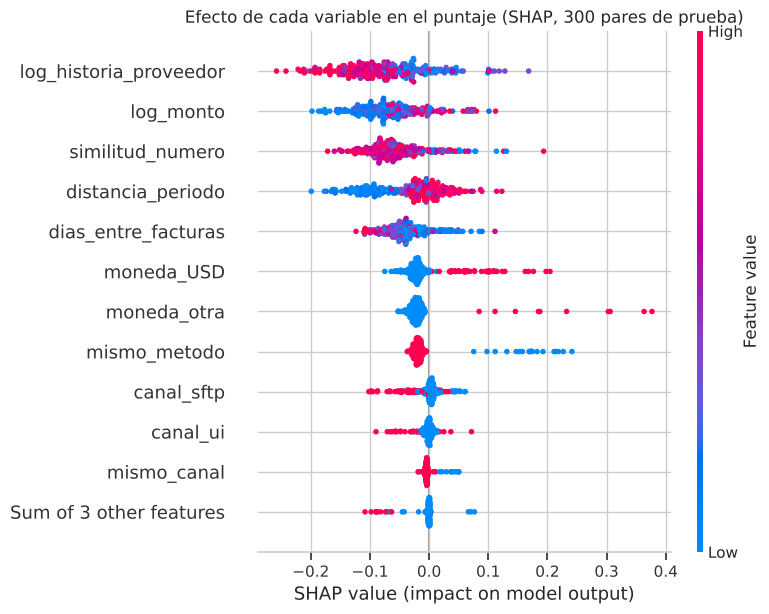

In [ ]:
shap.plots.beeswarm(valores, max_display=12, show=False)
plt.title("Efecto de cada variable en el puntaje (SHAP, 300 pares de prueba)"); plt.tight_layout()
plt.show()

In [ ]:
importancia = pd.Series(np.abs(valores.values).mean(axis=0),index=VARS).sort_values(ascending=False)
importancia.to_frame("SHAP medio absoluto").round(4)

,SHAP medio absoluto
log_historia_proveedor,0.087
log_monto,0.073
similitud_numero,0.067
distancia_periodo,0.050
dias_entre_facturas,0.046
moneda_USD,0.031
moneda_otra,0.029
mismo_metodo,0.028
canal_sftp,0.014
canal_ui,0.007


Explicación local del par con el puntaje mas alto de la muestra. Estos valores son los "motivos" que el dashboard muestra junto a cada alerta.


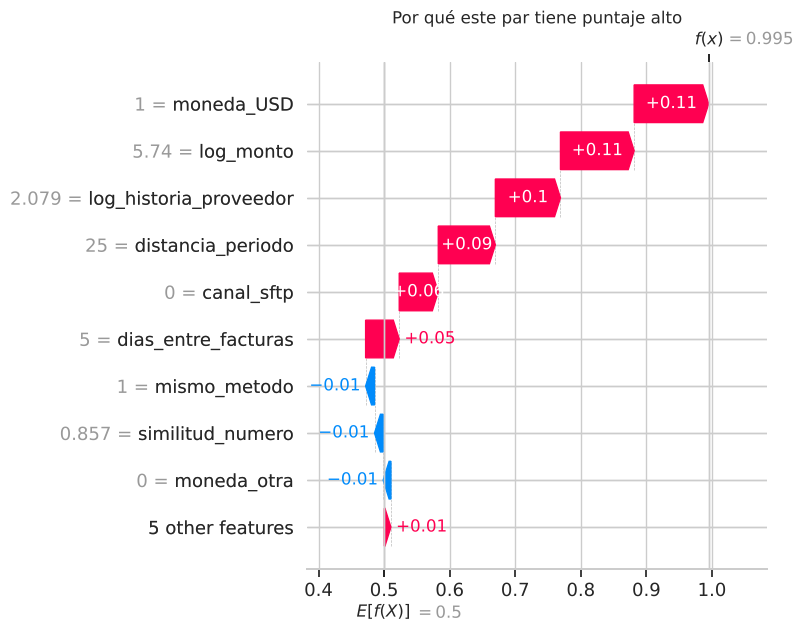

In [ ]:
j = int(np.argmax(predecir(X_muestra)))
shap.plots.waterfall(valores[j],max_display=10,show=False)
plt.title("Por qué este par tiene puntaje alto"); plt.tight_layout()
plt.show()

### 9.2 Pruebas de las hipotesis H2, H3 y H4

Igual que en el notebook 01 de la entrega 1, se aplica chi cuadrado a cada variable agrupada contra la etiqueta y se calcula la V de Cramér para medir el tamaño de la asociación. Se usa solo el conjunto de entrenamiento.


In [ ]:
train_h = X_train.assign(y=y_train)
train_h["cambio_canal"]=np.where(train_h["mismo_canal"]==1,"mismo canal","cambia de canal")
train_h["canal"] = pares.loc[X_train.index, "tipo_canal"]
train_h["tercil_historia"] = pd.qcut(train_h["log_historia_proveedor"], 3, labels=["poca", "media", "mucha"])
train_h["cuartil_monto"] = pd.qcut(train_h["log_monto"],4,labels=["Q1","Q2","Q3","Q4"])
filas_h = []
for hipotesis, var in [("H2", "cambio_canal"), ("H2", "canal"), ("H3", "tercil_historia"), ("H4", "cuartil_monto")]:
    t = pd.crosstab(train_h[var], train_h["y"])
    chi2, p, gl, _ = stats.chi2_contingency(t)
    v = np.sqrt(chi2 / (t.to_numpy().sum() * (min(t.shape) - 1)))
    filas_h.append({"hipótesis": hipotesis, "variable": var, "chi2": round(chi2, 2), "p-valor": f"{p:.4g}",
                  "V de Cramér": round(v, 3), "% con y = 1 por grupo": (t[1] / t.sum(axis=1) * 100).round(1).to_dict()})
pd.DataFrame(filas_h)

,hipótesis,variable,chi2,p-valor,V de Cramér,% con y = 1 por grupo
0,H2,cambio_canal,100.150,1.412e-23,0.121,"{'cambia de canal': 31.5, 'mismo canal': 8.9}"
1,H2,canal,10.270,0.03608,0.039,"{'csp': 9.4, 'email': 2.7, 'otro': 6.9, 'sftp'..."
2,H3,tercil_historia,110.740,8.96e-25,0.127,"{'poca': 14.5, 'media': 8.2, 'mucha': 5.7}"
3,H4,cuartil_monto,31.780,5.814e-07,0.068,"{'Q1': 7.5, 'Q2': 8.0, 'Q3': 9.8, 'Q4': 12.6}"


## 10. Cola de revisión

La cola son los pares en los que las dos facturas se aprobaron, ordenados por puntaje. Solo se puntúan los pares del conjunto de prueba: los de entrenamiento entraron al modelo con y = 0 y el Random Forest casi los memoriza, asi que su puntaje saldría artificialmente bajo. En la operación esto no pasa, porque cada semana el modelo puntua pares nuevos que no ha visto.


In [ ]:
cola = pares.loc[X_test.index]
cola = cola[cola["ambas_aprobadas"] == 1].copy()
cola["puntaje"] = mejor.predict_proba(X_test_esc.loc[cola.index])[:, 1]
cola = cola.sort_values("puntaje",ascending=False)
print(f"Pares en la cola (prueba): {len(cola):,} | con puntaje >= 0,5: {(cola['puntaje'] >= 0.5).sum():,} | >= 0,8: {(cola['puntaje'] >= 0.8).sum():,}")
cola[["proveedor_id", "fecha_anterior", "fecha", "monto_cad", "dias_entre_facturas", "similitud_numero",
        "mismo_canal", "puntaje"]].head(10)

Pares en la cola (prueba): 2,074 | con puntaje >= 0,5: 84 | >= 0,8: 6


,proveedor_id,fecha_anterior,fecha,monto_cad,dias_entre_facturas,similitud_numero,mismo_canal,puntaje
9869,PROV_1832,2026-03-07,2026-03-07,"108,620.000",0,0.667,1,0.995
3278,PROV_3261,2025-03-11,2025-03-13,"14,407.350",2,0.800,0,0.980
914,PROV_0720,2024-11-02,2024-11-02,"20,285.760",0,0.812,1,0.965
4496,PROV_3315,2025-05-19,2025-05-19,"21,305.500",0,0.769,1,0.880
4398,PROV_0728,2025-04-16,2025-05-13,"322,529.480",27,0.667,1,0.840
7717,PROV_1923,2025-10-28,2025-10-29,"512,226.340",1,0.824,1,0.805
5818,PROV_0720,2025-05-26,2025-07-22,"28,768.900",57,0.812,1,0.795
689,PROV_1923,2024-10-18,2024-10-18,"506,544.250",0,0.875,1,0.795
6057,PROV_1191,2025-06-02,2025-08-05,"82,942.000",64,0.941,1,0.795
4035,PROV_0268,2025-04-09,2025-04-25,"19,210.000",16,0.636,0,0.790


## 11. Revision del Banco

Esta sección lee el Excel que devuelve el Banco con los 30 pares revisados (archivo Revision_casos_duplicados_Banco_respuesta.xlsx en data/raw/). Con esas respuestas se calcula la precision real de la cola y se compara con la meta del KPI de la entrega 1 (30% o más). Si el archivo todavia no está, la sección lo indica.


In [ ]:
if os.path.exists(REVISION_BANCO):
    rev=pd.read_excel(REVISION_BANCO,sheet_name="Facturas")
    resp = rev["¿Se pagó dos veces?"].dropna()
    resp = resp[resp.isin(["Sí", "No"])]
    revisados, si=len(resp), int((resp=="Sí").sum())
    PRECISION_REAL,lo,hi=ic_bootstrap((resp=="Sí").astype(int))
    print(f"Revisados: {revisados} | pagados dos veces: {si} | precisión real: {PRECISION_REAL:.1%} (IC 95%: {lo:.1%} a {hi:.1%})")
else:
    PRECISION_REAL=None
    print("Pendiente: el Banco todavía no ha devuelto la revisión.")

Pendiente: el Banco todavía no ha devuelto la revisión.


## 12. Impacto con la formula de Provost

Se usa una matriz de costo-beneficio (marco de Provost) adaptada al caso. Revisar un par cuesta c (el tiempo del analista). Si el par es un pago doble, el Banco recupera una fracción r del monto V de la factura repetida.

- VP (se revisa y era pago doble) (valor: r · V − c)
- FP (se revisa y no lo era) (valor: −c)
- FN y VN (valor: 0)

La precisión de equilibrio es P_e = c / (r · V): si la precision real de la cola supera ese valor, revisar genera valor.

Supuestos (el Banco no ha enviado sus cifras; se cambian aquí cuando lleguen):

- Minutos por caso (bajo: 15; base: 30; alto: 60; fuente: Centime: cada excepcion de cuentas por pagar toma de 15 a 60 minutos de un analista)
- Costo por hora (CAD) (bajo: 25,48; base: 41,67; alto: 72,12; fuente: Job Bank Canadá (actualizado el 18-nov-2026): salario bajo, mediano y alto de auditores financieros y contadores (NOC 11100))
- Fracción recuperada r (bajo: 10%; base: 50%; alto: 100%; fuente: Sensibilidad; no hay una cifra pública confiable)


In [ ]:
MINUTOS = {"bajo": 15, "base": 30, "alto": 60}
COSTO_HORA={"bajo": 25.48, "base": 41.67, "alto": 72.12}
c = {k: MINUTOS[k] / 60 * COSTO_HORA[k] for k in MINUTOS}
print("Costo de revisar un caso, c (CAD):", {k: round(v, 2) for k, v in c.items()})
K=50  # 50 casos: el tamaño de la cola del KPI de la entrega 1
V = cola.head(K)["monto_cad"].median()
print(f"Mediana del monto en los primeros {K} pares de la cola: V = {V:,.0f} CAD")
filas_p=[]
for r in [0.10, 0.50, 1.00]:
    for escenario in ["base", "alto"]:
        filas_p.append({"r": r, "costo": escenario, "c (CAD)": c[escenario], "P_e (precisión de equilibrio)": c[escenario] / (r * V)})
pd.DataFrame(filas_p).round({"r": 2, "c (CAD)": 2, "P_e (precisión de equilibrio)": 4})

Costo de revisar un caso, c (CAD): {'bajo': 6.37, 'base': 20.84, 'alto': 72.12}
Mediana del monto en los primeros 50 pares de la cola: V = 27,105 CAD


,r,costo,c (CAD),P_e (precisión de equilibrio)
0,0.100,base,20.840,0.008
1,0.100,alto,72.120,0.027
2,0.500,base,20.840,0.002
3,0.500,alto,72.120,0.005
4,1.000,base,20.840,0.001
5,1.000,alto,72.120,0.003


El valor esperado por caso revisado, con la formula de Provost, es P · (r · V − c) + (1 − P) · (−c), donde P es la precision real. Como todavia no está la precision que confirme el Banco, se muestran tres valores de P alrededor de la meta del KPI (30%) y el beneficio de revisar 50 casos.


In [ ]:
precisiones = [0.05,0.10,0.30] + ([PRECISION_REAL] if PRECISION_REAL is not None else [])
filas_v = []
for P in precisiones:
    for r in [0.10, 0.50, 1.00]:
        ve=P * (r * V - c["base"]) + (1 - P) * (-c["base"])
        filas_v.append({"precisión real P": P,"r": r,"valor esperado por caso (CAD)": ve,f"beneficio por {K} casos (CAD)": ve * K})
tabla_valor = pd.DataFrame(filas_v)
tabla_valor.round({"precisión real P": 2, "r": 2, "valor esperado por caso (CAD)": 0, f"beneficio por {K} casos (CAD)": 0})

,precisión real P,r,valor esperado por caso (CAD),beneficio por 50 casos (CAD)
0,0.050,0.100,115.000,"5,734.000"
1,0.050,0.500,657.000,"32,839.000"
2,0.050,1.000,"1,334.000","66,720.000"
3,0.100,0.100,250.000,"12,511.000"
4,0.100,0.500,"1,334.000","66,720.000"
5,0.100,1.000,"2,690.000","134,483.000"
6,0.300,0.100,792.000,"39,616.000"
7,0.300,0.500,"4,045.000","202,245.000"
8,0.300,1.000,"8,111.000","405,531.000"


Con un monto mediano del orden de decenas de miles de CAD y un costo por caso entre 20 y 72 CAD, la precision de equilibrio queda por debajo del 3% en todos los escenarios, incluso si solo se recupera el 10% del monto. El costo de revisar casi no pesa: el valor del modelo depende de cuantos de los casos marcados sean pagos dobles de verdad, y esa cifra solo la puede dar la revisión del Banco.